# Proyek Akhir Data Science - Analisis dan Prediksi Pembatalan Reservasi Hotel: Pendekatan *Data Science* untuk Mengidentifikasi Faktor Risiko dan Mendukung Strategi *Overbooking*

---
Kelompok - Aliansi Cinta dan Jagung Bakar:
- Vania Christabella		(123240235)
- Jelita Syahwa Nabila		(123240243)
- Mutiara Rahmawati Zalsa	(123240257)
- Aliffa Izza Ferryna   	(123240258)
---


## Business Understanding

### Latar Belakang
Pembatalan reservasi merupakan salah satu permasalahan dalam pengelolaan hotel karena dapat memengaruhi ketersediaan kamar dan potensi pendapatan. Ketika tamu membatalkan reservasi, kamar yang sebelumnya telah dipesan berpotensi tidak terjual kembali, terutama apabila pembatalan terjadi mendekati tanggal kedatangan.

Di sisi lain, hotel perlu mengantisipasi kemungkinan pembatalan agar dapat mengelola reservasi secara lebih efektif. Salah satu pendekatan yang dapat digunakan adalah Data Science untuk menganalisis pola pembatalan berdasarkan karakteristik reservasi dan membangun model yang dapat memprediksi kemungkinan pembatalan.

Proyek ini menggunakan Hotel Booking Demand Dataset yang berisi informasi historis reservasi hotel, seperti waktu pemesanan, jenis hotel, segmen pasar, jenis deposit, serta status pembatalan. Melalui analisis data dan pemodelan klasifikasi, proyek ini bertujuan mengidentifikasi pola yang berkaitan dengan pembatalan dan memperkirakan risiko pembatalan reservasi.

### Solusi
Solusi yang diusulkan adalah menerapkan pendekatan Data Science melalui analisis eksplorasi data (*Exploratory Data Analysis* atau EDA) dan pemodelan klasifikasi (*supervised learning*). EDA digunakan untuk memahami distribusi pembatalan serta hubungan antara karakteristik reservasi dan status pembatalan. Selanjutnya, model klasifikasi digunakan untuk memprediksi apakah suatu reservasi berpotensi dibatalkan (kelas 1) atau tidak (kelas 0) berdasarkan informasi yang sudah tersedia **saat reservasi dibuat**.

Hasil analisis dan prediksi diharapkan menjadi bahan pertimbangan bagi pengelola hotel dalam mengidentifikasi reservasi berisiko, meningkatkan strategi pengelolaan kamar, dan mempertimbangkan kebijakan *overbooking* secara lebih terukur. Namun, keputusan *overbooking* tetap perlu mempertimbangkan kapasitas kamar, potensi kerugian, serta risiko ketika tamu yang telah memesan ternyata tetap datang.


## Import Library

In [188]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report

## Memuat Dataset

In [189]:
# Membaca dataset hotel bookings
df = pd.read_csv("DATA/hotel_bookings.csv")
print("Ukuran dataset asli (baris, kolom):", df.shape)
df.head()

Ukuran dataset asli (baris, kolom): (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [190]:
# Melihat jumlah baris dan kolom serta jenis data dalam dataset asli
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [191]:
# Melihat statistik deskriptif dataset asli
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


## Data Understanding menggunakan Random Sampling

Urutan Data Understanding yang akan dikerjakan:
1. Melihat gambaran dataset — mengenali baris, kolom, dan contoh data.
2. Memeriksa missing value — mengetahui nilai kosong pada setiap kolom.
3. Memeriksa duplikasi — mengetahui jumlah baris yang identik.
4. Memahami distribusi target — melihat perbandingan reservasi yang dibatalkan dan tidak dibatalkan.
5. Memeriksa nilai yang tidak wajar — mencari data yang perlu ditinjau lebih lanjut.
6. Melakukan EDA dan visualisasi — mencari pola pembatalan berdasarkan karakteristik reservasi.

### 2.1 Sumber Data dan Kesiapan Data

In [192]:
# Mengambil sampel acak 50.000 baris tanpa pengembalian
df_hotel = df.sample(
    n=50_000, 
    random_state=42, 
    replace=False
).reset_index(drop=True)

print("Ukuran dataset asli  :", df.shape)
print("Ukuran dataset sampel:", df_hotel.shape)

Ukuran dataset asli  : (119390, 32)
Ukuran dataset sampel: (50000, 32)


In [193]:
# Melihat jumlah baris dan kolom serta jenis data dalam dataset sampel
df_hotel.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 32 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   hotel                           50000 non-null  object 
 1   is_canceled                     50000 non-null  int64  
 2   lead_time                       50000 non-null  int64  
 3   arrival_date_year               50000 non-null  int64  
 4   arrival_date_month              50000 non-null  object 
 5   arrival_date_week_number        50000 non-null  int64  
 6   arrival_date_day_of_month       50000 non-null  int64  
 7   stays_in_weekend_nights         50000 non-null  int64  
 8   stays_in_week_nights            50000 non-null  int64  
 9   adults                          50000 non-null  int64  
 10  children                        50000 non-null  float64
 11  babies                          50000 non-null  int64  
 12  meal                            

### 2.2 Pemahaman Struktur dan Variabel

In [194]:
# Melihat lima baris pertama dataset sampel
df_hotel.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,203,2016,December,49,2,2,5,2,...,No Deposit,250.0,NaN,0,Transient,66.8,0,0,Check-Out,2016-12-09
1,City Hotel,1,82,2015,July,29,16,0,3,2,...,No Deposit,9.0,NaN,0,Transient,76.5,0,0,Canceled,2015-07-16
2,City Hotel,0,25,2016,December,53,27,0,3,3,...,No Deposit,220.0,NaN,0,Transient-Party,60.0,0,1,Check-Out,2016-12-30
3,City Hotel,0,1,2016,March,11,9,0,1,1,...,No Deposit,9.0,NaN,0,Transient-Party,95.0,0,0,Check-Out,2016-03-10
4,City Hotel,0,70,2017,April,16,16,2,2,2,...,No Deposit,9.0,NaN,0,Transient,108.0,0,0,Check-Out,2017-04-20


In [195]:
# Melihat ringkasan struktur dan karakteristik setiap kolom
struktur_data = pd.DataFrame({
    "Nama Kolom": df_hotel.columns,
    "Tipe Data": df_hotel.dtypes.astype(str).values,
    "Jumlah Nilai Terisi": df_hotel.notna().sum().values,
    "Jumlah Nilai Unik": df_hotel.nunique(dropna=True).values
})

display(struktur_data)

,Nama Kolom,Tipe Data,Jumlah Nilai Terisi,Jumlah Nilai Unik
0,hotel,object,50000,2
1,is_canceled,int64,50000,2
2,lead_time,int64,50000,470
3,arrival_date_year,int64,50000,3
4,arrival_date_month,object,50000,12
5,arrival_date_week_number,int64,50000,53
6,arrival_date_day_of_month,int64,50000,31
7,stays_in_weekend_nights,int64,50000,14
8,stays_in_week_nights,int64,50000,28
9,adults,int64,50000,10


In [196]:
# Melihat statistik deskriptif dataset sampel
df_hotel.describe().T

,count,mean,std,min,25%,50%,75%,max
is_canceled,50000.0,0.371600,0.483237,0.00,0.0000,0.0,1.0,1.0
lead_time,50000.0,104.030080,106.953591,0.00,18.0000,69.0,161.0,737.0
arrival_date_year,50000.0,2016.157220,0.708288,2015.00,2016.0000,2016.0,2017.0,2017.0
arrival_date_week_number,50000.0,27.156940,13.592113,1.00,16.0000,28.0,38.0,53.0
arrival_date_day_of_month,50000.0,15.802880,8.754873,1.00,8.0000,16.0,23.0,31.0
stays_in_weekend_nights,50000.0,0.923300,0.992168,0.00,0.0000,1.0,2.0,19.0
stays_in_week_nights,50000.0,2.491960,1.896082,0.00,1.0000,2.0,3.0,50.0
adults,50000.0,1.857600,0.550898,0.00,2.0000,2.0,2.0,55.0
children,50000.0,0.102120,0.396856,0.00,0.0000,0.0,0.0,10.0
babies,50000.0,0.007960,0.098065,0.00,0.0000,0.0,0.0,9.0


In [197]:
# Melihat nilai kategori pada beberapa kolom penting
kolom_kategori = [
    "hotel",
    "is_canceled",
    "deposit_type",
    "market_segment",
    "distribution_channel",
    "customer_type",
    "arrival_date_month"
]

for kolom in kolom_kategori:
    print(f"\nNilai unik pada kolom {kolom}:")
    print(sorted(df_hotel[kolom].dropna().unique()))


Nilai unik pada kolom hotel:
['City Hotel', 'Resort Hotel']

Nilai unik pada kolom is_canceled:
[np.int64(0), np.int64(1)]

Nilai unik pada kolom deposit_type:
['No Deposit', 'Non Refund', 'Refundable']

Nilai unik pada kolom market_segment:
['Aviation', 'Complementary', 'Corporate', 'Direct', 'Groups', 'Offline TA/TO', 'Online TA']

Nilai unik pada kolom distribution_channel:
['Corporate', 'Direct', 'GDS', 'TA/TO', 'Undefined']

Nilai unik pada kolom customer_type:
['Contract', 'Group', 'Transient', 'Transient-Party']

Nilai unik pada kolom arrival_date_month:
['April', 'August', 'December', 'February', 'January', 'July', 'June', 'March', 'May', 'November', 'October', 'September']


In [198]:
# Melihat jumlah dan persentase kategori
kolom_kategori_frekuensi = [
    "hotel",
    "is_canceled",
    "deposit_type",
    "market_segment",
    "distribution_channel",
    "customer_type",
    "arrival_date_month"
]

for kolom in kolom_kategori_frekuensi:
    print(f"\nDistribusi kategori: {kolom}")

    distribusi = pd.DataFrame({
        "Jumlah": df_hotel[kolom].value_counts(dropna=False),
        "Persentase (%)": (df_hotel[kolom].value_counts(
                            normalize=True, 
                            dropna=False
                        ) * 100).round(2)
    })
    display(distribusi)


Distribusi kategori: hotel


,Jumlah,Persentase (%)
hotel,,
City Hotel,33247,66.49
Resort Hotel,16753,33.51



Distribusi kategori: is_canceled


,Jumlah,Persentase (%)
is_canceled,,
0,31420,62.84
1,18580,37.16



Distribusi kategori: deposit_type


...

,Jumlah,Persentase (%)
distribution_channel,,
TA/TO,40916,81.83
Direct,6184,12.37
Corporate,2823,5.65
GDS,76,0.15
Undefined,1,0.00



Distribusi kategori: customer_type


,Jumlah,Persentase (%)
customer_type,,
Transient,37515,75.03
Transient-Party,10583,21.17
Contract,1669,3.34
Group,233,0.47



Distribusi kategori: arrival_date_month


,Jumlah,Persentase (%)
arrival_date_month,,
August,5830,11.66
July,5356,10.71
May,4865,9.73
June,4659,9.32
October,4655,9.31
April,4600,9.20
September,4426,8.85
March,4092,8.18
February,3376,6.75


### 2.3 Periksa Kualitas Data
Bagian ini mencatat kelengkapan data, duplikasi, distribusi target, serta nilai yang perlu ditinjau. Di tahap ini, kita belum melakukan pembersihan.

In [199]:

# Menghitung jumlah missing value dan persentasenya
missing_data = df_hotel.isnull().sum().reset_index()    
missing_data.columns = ["Kolom", "Jumlah Missing Value"]
missing_data["Persentase Missing Value (%)"] = missing_data[
    "Jumlah Missing Value"] / len(df_hotel) * 100
missing_data = missing_data[
    missing_data["Jumlah Missing Value"] > 0].sort_values(
    "Jumlah Missing Value", ascending=False)
display(missing_data)

,Kolom,Jumlah Missing Value,Persentase Missing Value (%)
24,company,47155,94.310
23,agent,6842,13.684
13,country,209,0.418


Terdapat tiga kolom yang memiliki nilai kosong: `company`, `agent`, dan `country`. Berikut penjelasan tiap kolomnya:
1. Dari 50.000 baris, hanya 2.845 baris yang memiliki nilai pada kolom `company`.
2. Sekitar 13,68% data tidak memiliki informasi `agent` pemesanan, sehingga diperlukan cara penanganan pada tahap Data Preparation.
3. `country` dengan persentase 0.42% memiliki nilai kosong yang relatif lebih sedikit, namun perlu memutuskan cara menangani nilai kosong tersebut berdasarkan kebutuhan analisis.

In [200]:
# Menghitung jumlah baris duplikat
jumlah_duplikat = df_hotel.duplicated().sum()
print("Jumlah baris duplikat    :", jumlah_duplikat)
print(f"Persentase baris duplikat: {round(jumlah_duplikat / len(df_hotel) * 100, 2)}%")

Jumlah baris duplikat    : 10735
Persentase baris duplikat: 21.47%


In [201]:
# Menghitung distribusi jumlah reservasi
print("Jumlah reservasi status pembatalan:")
print(df_hotel["is_canceled"].value_counts())

# Menghitung distribusi persentase status pembatalan
print("\nPersentase setiap status pembatalan:")
print((df_hotel["is_canceled"]
       .value_counts(normalize=True) * 100).round(2)
)

Jumlah reservasi status pembatalan:
is_canceled
0    31420
1    18580
Name: count, dtype: int64

Persentase setiap status pembatalan:
is_canceled
0    62.84
1    37.16
Name: proportion, dtype: float64


Status `is_canceled`:
- 0 — tidak dibatalkan
- 1 — dibatalkan

Berdasarkan analisis 50000 dataset sampel dapat disimpulkan:
- 31420 reservasi (62.84%) tidak dibatalkan, dan
- 18580 reservasi (37.16%) dibatalkan.

Artinya, jumlah reservasi yang tidak dibatalkan lebih banyak daripada yang dibatalkan.

In [202]:
# Memeriksa kondisi yang tidak wajar pada dataset
total_nights = (
    df_hotel["stays_in_weekend_nights"] +
    df_hotel["stays_in_week_nights"]
)
total_guests = (
    df_hotel["adults"].fillna(0) +
    df_hotel["children"].fillna(0) +
    df_hotel["babies"].fillna(0)
)

periksa_anomali = {
    "Reservasi tanpa tamu": (total_guests == 0).sum(),
    "Reservasi dengan adults > 10": (df_hotel["adults"] > 10).sum(),
    "Reservasi dengan ADR < 0": (df_hotel["adr"] < 0).sum(),
    "Reservasi dengan ADR = 0": (df_hotel["adr"] == 0).sum(),
    "Reservasi dengan lama menginap = 0 malam": (total_nights == 0).sum(),
    "Reservasi dengan lama menginap > 30 malam": (total_nights > 30).sum()
}

display(pd.DataFrame(
    periksa_anomali.items(),
    columns=["Kondisi", "Jumlah Baris"]
))

,Kondisi,Jumlah Baris
0,Reservasi tanpa tamu,69
1,Reservasi dengan adults > 10,2
2,Reservasi dengan ADR < 0,1
3,Reservasi dengan ADR = 0,780
4,Reservasi dengan lama menginap = 0 malam,298
5,Reservasi dengan lama menginap > 30 malam,8


Penjelasan:
- `total_nights` menghitung total malam akhir pekan dan malam hari kerja.
- `total_guests` menjumlahkan orang dewasa, anak-anak, dan bayi.
- Kondisi lainnya menandai nilai yang perlu ditinjau berdasarkan makna variabel.
    1. (69) reservasi tanpa tamu: periksa apakah jumlah tamunya memang nol atau ada nilai kosong yang ikut dianggap nol dalam perhitungan.
    2. (2) reservasi dengan adults > 10: periksa apakah ini reservasi rombongan atau kesalahan pencatatan.
    3. (1) reservasi dengan adr < 0: periksa baris tersebut sebelum memutuskan penanganannya.
    4. (780) reservasi dengan adr = 0: jangan otomatis dihapus karena nilai nol belum tentu salah.
    5. (298) reservasi dengan lama menginap nol malam: periksa konteksnya sebelum menentukan apakah data perlu ditangani.
    6. (8) reservasi dengan lama menginap lebih dari 30 malam: periksa apakah masa menginap tersebut masih masuk akal untuk data reservasi hotel.

In [203]:
# Melihat reservasi dengan ADR negatif
df_hotel.loc[ df_hotel["adr"] < 0,[
        "hotel", "is_canceled", "lead_time", "adults",
        "children", "babies", "adr"
    ]
]

,hotel,is_canceled,lead_time,adults,children,babies,adr
38218,Resort Hotel,0,195,2,0.0,0,-6.38


Ditemukan satu reservasi dengan nilai ADR negatif sebesar -6,38. Nilai tersebut perlu ditinjau lebih lanjut pada tahap Data Preparation sebelum ditentukan penanganannya.

In [204]:
# Mendeteksi kandidat outlier menggunakan metode IQR
kolom_iqr = [
    "lead_time", "adr", "adults",
    "children", "babies",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "days_in_waiting_list"
]

hasil_iqr = []
for kolom in kolom_iqr:
    data = df_hotel[kolom].dropna()

    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    iqr = q3 - q1

    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr

    kandidat = (data < batas_bawah) | (data > batas_atas)
    hasil_iqr.append({
        "Kolom": kolom,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Batas Bawah": batas_bawah,
        "Batas Atas": batas_atas,
        "Jumlah Kandidat Outlier": int(kandidat.sum()),
        "Persentase (%)": round(kandidat.mean() * 100, 2)
    })
    
display(pd.DataFrame(hasil_iqr).round(2))

,Kolom,Q1,Q3,IQR,Batas Bawah,Batas Atas,Jumlah Kandidat Outlier,Persentase (%)
0,lead_time,18.00,161.0,143.00,-196.50,375.50,1256,2.51
1,adr,69.18,126.0,56.82,-16.04,211.23,1554,3.11
2,adults,2.00,2.0,0.00,2.00,2.00,12428,24.86
3,children,0.00,0.0,0.00,0.00,0.00,3531,7.06
4,babies,0.00,0.0,0.00,0.00,0.00,383,0.77
5,stays_in_weekend_nights,0.00,2.0,2.00,-3.00,5.00,95,0.19
6,stays_in_week_nights,1.00,3.0,2.00,-2.00,6.00,1416,2.83
7,days_in_waiting_list,0.00,0.0,0.00,0.00,0.00,1513,3.03


Menghitung jumlah nilai yang berada di luar batas IQR pada masing-masing kolom. Hasilnya merupakan kandidat outlier, bukan daftar kesalahan data yang sudah terbukti.

Mengapa kita tidak langsung menghapusnya? Karena reservasi dengan lead_time yang panjang atau tarif yang tinggi masih mungkin benar-benar terjadi. Kita perlu melihat konteksnya dan mempertimbangkan dampaknya terhadap analisis.

Pemeriksaan IQR ini juga tidak menggantikan pemeriksaan anomali sebelumnya. Keduanya memiliki tujuan berbeda: IQR mendeteksi nilai ekstrem secara statistik, sedangkan pemeriksaan sebelumnya menggunakan kondisi yang relevan dengan arti variabel.

In [205]:
# Memeriksa rentang tahun, minggu, dan hari kedatangan
print("Tahun kedatangan:", sorted(df_hotel["arrival_date_year"].dropna().unique()))

print("Rentang nomor minggu kedatangan:",
    df_hotel["arrival_date_week_number"].min(),
    "—",
    df_hotel["arrival_date_week_number"].max()
)

print("Rentang hari dalam bulan:",
    df_hotel["arrival_date_day_of_month"].min(),
    "—",
    df_hotel["arrival_date_day_of_month"].max()
)

print("Reservasi dengan lama menginap negatif:",(total_nights < 0).sum())

print("Reservasi dengan lead_time negatif:",
    (df_hotel["lead_time"] < 0).sum()
)

Tahun kedatangan: [np.int64(2015), np.int64(2016), np.int64(2017)]
Rentang nomor minggu kedatangan: 1 — 53
Rentang hari dalam bulan: 1 — 31
Reservasi dengan lama menginap negatif: 0
Reservasi dengan lead_time negatif: 0


Memastikan bahwa nilai waktu dan durasi berada dalam rentang dasar yang masuk akal. Nilai nomor minggu dan hari kedatangan tetap perlu ditafsirkan sesuai definisi dataset.

Kombinasi tanggal yang tidak membentuk tanggal kalender lengkap belum tentu dapat dipastikan hanya dengan pemeriksaan ini, karena tahun, bulan, dan hari disimpan dalam kolom terpisah. Jika nantinya diperlukan, kita bisa membuat tanggal kedatangan sementara untuk validasi lebih lanjut.

### 2.4 EDA (Exploratory Data Analysis)

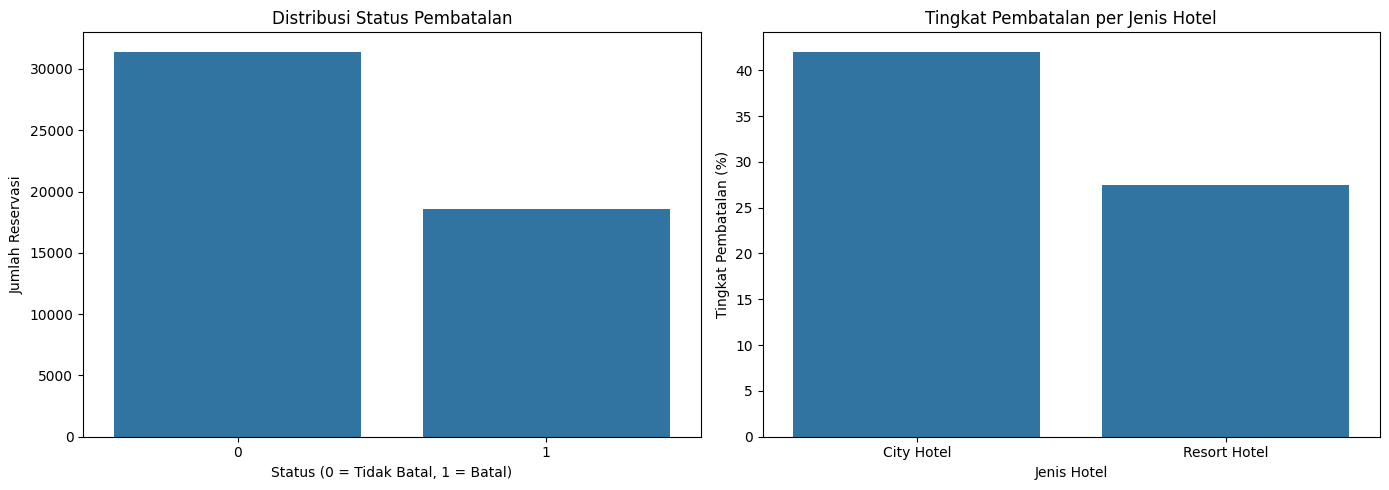

In [206]:
# Visualisasi distribusi status pembatalan reservasi dan tingkat pembatalan per jenis hotel
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df_hotel, x="is_canceled", ax=ax[0])
ax[0].set_title("Distribusi Status Pembatalan")
ax[0].set_xlabel("Status (0 = Tidak Batal, 1 = Batal)")
ax[0].set_ylabel("Jumlah Reservasi")

hotel_rate = df_hotel.groupby("hotel")["is_canceled"].mean() * 100
sns.barplot(x=hotel_rate.index, y=hotel_rate.values, ax=ax[1])
ax[1].set_title("Tingkat Pembatalan per Jenis Hotel")
ax[1].set_xlabel("Jenis Hotel")
ax[1].set_ylabel("Tingkat Pembatalan (%)")

plt.tight_layout()
plt.show()

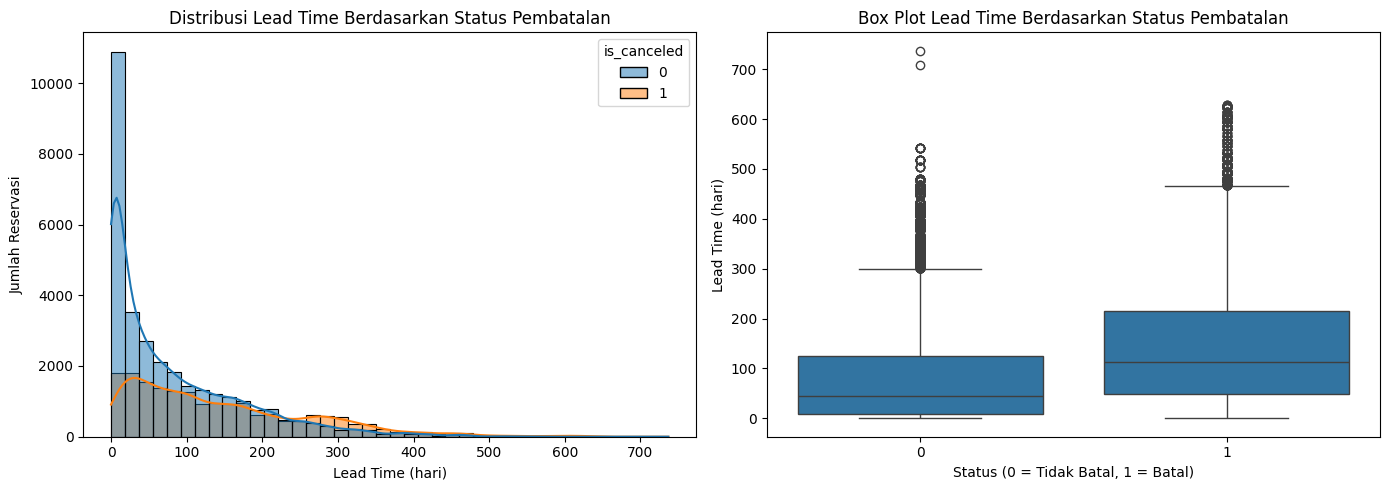

In [207]:
# Visualisasi lead time berdasarkan status pembatalan (histogram dan box plot)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df_hotel, x="lead_time", hue="is_canceled", kde=True, bins=40, stat="count", common_norm=False, ax=ax[0])
ax[0].set_title("Distribusi Lead Time Berdasarkan Status Pembatalan")
ax[0].set_xlabel("Lead Time (hari)")
ax[0].set_ylabel("Jumlah Reservasi")

sns.boxplot(data=df_hotel, x="is_canceled", y="lead_time", ax=ax[1])
ax[1].set_title("Box Plot Lead Time Berdasarkan Status Pembatalan")
ax[1].set_xlabel("Status (0 = Tidak Batal, 1 = Batal)")
ax[1].set_ylabel("Lead Time (hari)")

plt.tight_layout()
plt.show()

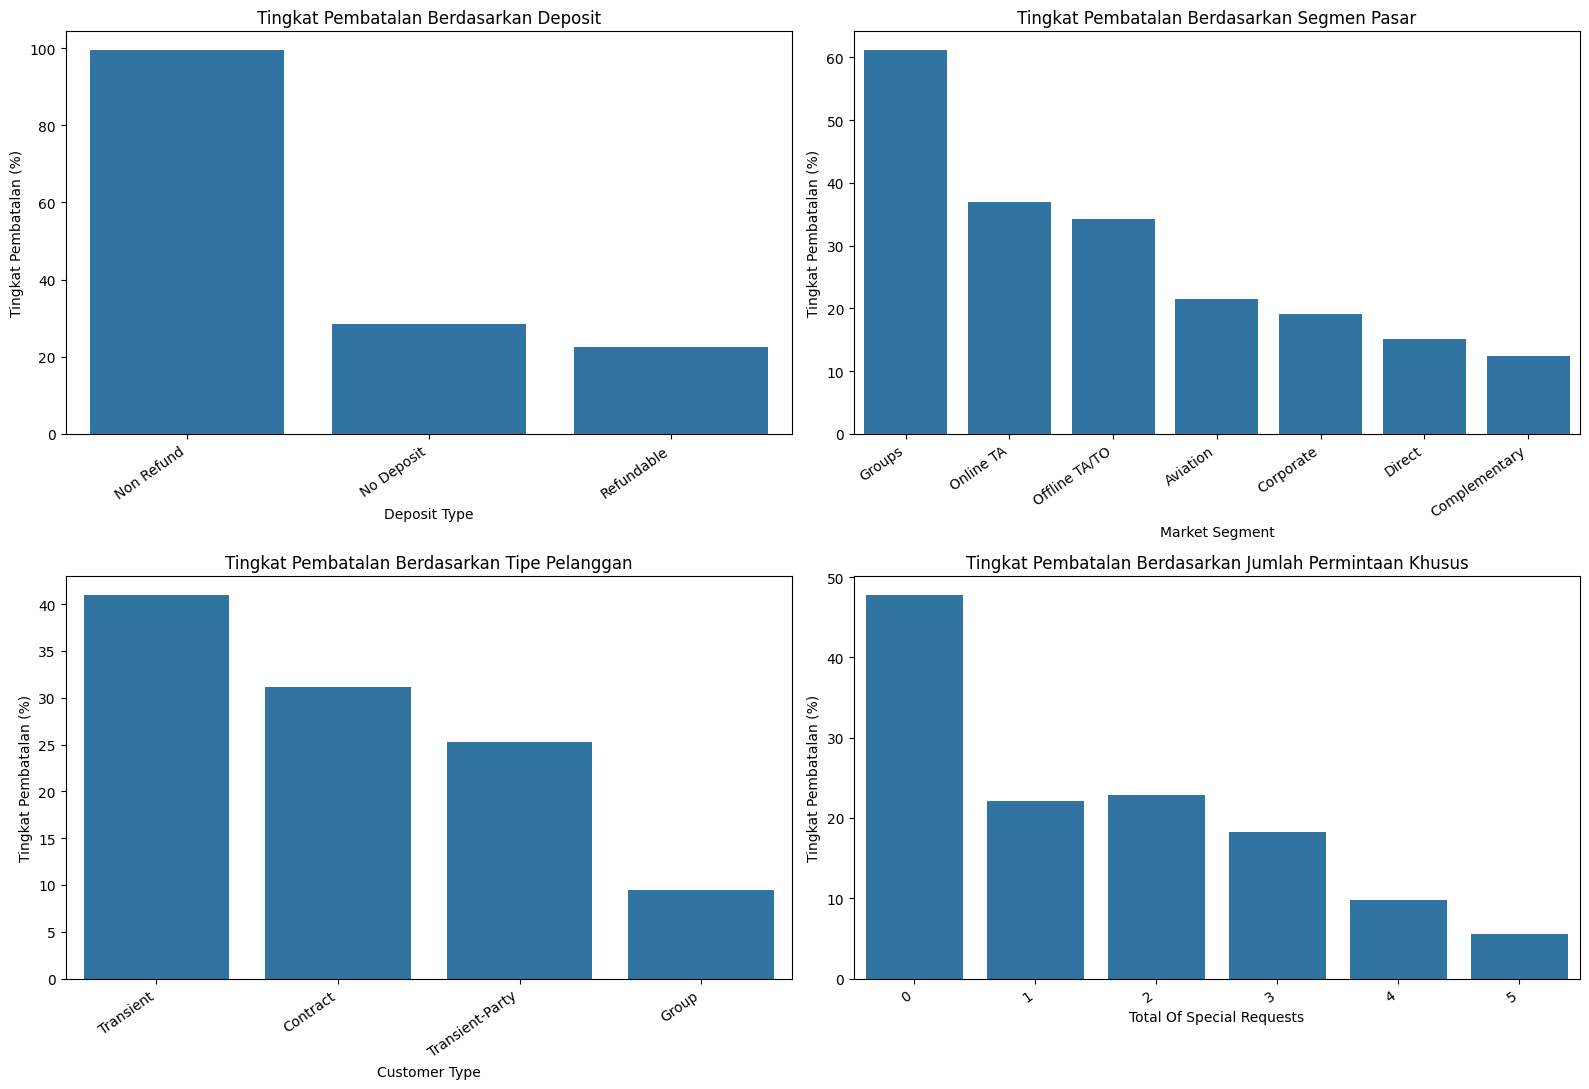

In [208]:

# Visualisasi tingkat pembatalan berdasarkan karakteristik reservasi:
# tipe deposit, segmen pasar, tipe pelanggan, dan jumlah permintaan khusus

kolom_perbandingan = [
    ("deposit_type", "Tingkat Pembatalan Berdasarkan Deposit"),
    ("market_segment", "Tingkat Pembatalan Berdasarkan Segmen Pasar"),
    ("customer_type", "Tingkat Pembatalan Berdasarkan Tipe Pelanggan"),
    ("total_of_special_requests", "Tingkat Pembatalan Berdasarkan Jumlah Permintaan Khusus")
]

fig, ax = plt.subplots(2, 2, figsize=(16, 11))
ax = ax.flatten()

for i, (kolom, judul) in enumerate(kolom_perbandingan):
    data_plot = (
        df_hotel.groupby(kolom, dropna=False)["is_canceled"].mean().mul(100)
        .reset_index(name="Tingkat Pembatalan (%)").sort_values(by="Tingkat Pembatalan (%)", ascending=False)
    )
    sns.barplot(data=data_plot, x=kolom, y="Tingkat Pembatalan (%)", ax=ax[i])
    ax[i].set_title(judul)
    ax[i].set_xlabel(kolom.replace("_", " ").title())
    ax[i].set_ylabel("Tingkat Pembatalan (%)")
    ax[i].tick_params(axis="x", rotation=35)
    for label in ax[i].get_xticklabels(): label.set_ha("right")

plt.tight_layout()
plt.show()


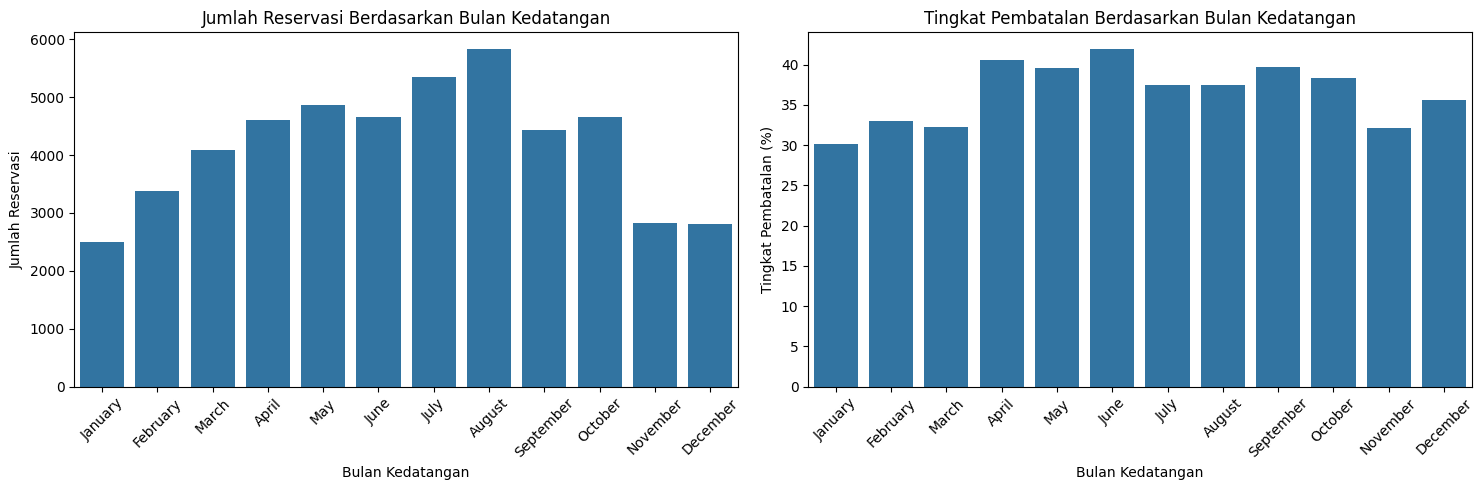

In [209]:
# Visualisasi tingkat pembatalan per bulan kedatangan berdasarkan jumlah reservasi dan tingkat pembatalan (%)
urutan_bulan = [
    "January", "February", "March", "April", "May", "June", "July", 
    "August", "September", "October", "November", "December"
]

df_bulan = (df_hotel.groupby("arrival_date_month").agg(
        Jumlah_Reservasi=("is_canceled", "size"),
        Jumlah_Dibatalkan=("is_canceled", "sum"),
        Tingkat_Pembatalan=("is_canceled", "mean")
    ).reindex(urutan_bulan).reset_index().rename(columns={"arrival_date_month": "Bulan"})
)

df_bulan["Tingkat_Pembatalan"] = (df_bulan["Tingkat_Pembatalan"] * 100)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=df_bulan, x="Bulan", y="Jumlah_Reservasi", ax=ax[0])
ax[0].set_title("Jumlah Reservasi Berdasarkan Bulan Kedatangan")
ax[0].set_xlabel("Bulan Kedatangan")
ax[0].set_ylabel("Jumlah Reservasi")
ax[0].tick_params(axis="x", rotation=45)

sns.barplot(data=df_bulan, x="Bulan", y="Tingkat_Pembatalan", ax=ax[1])
ax[1].set_title("Tingkat Pembatalan Berdasarkan Bulan Kedatangan")
ax[1].set_xlabel("Bulan Kedatangan")
ax[1].set_ylabel("Tingkat Pembatalan (%)")
ax[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


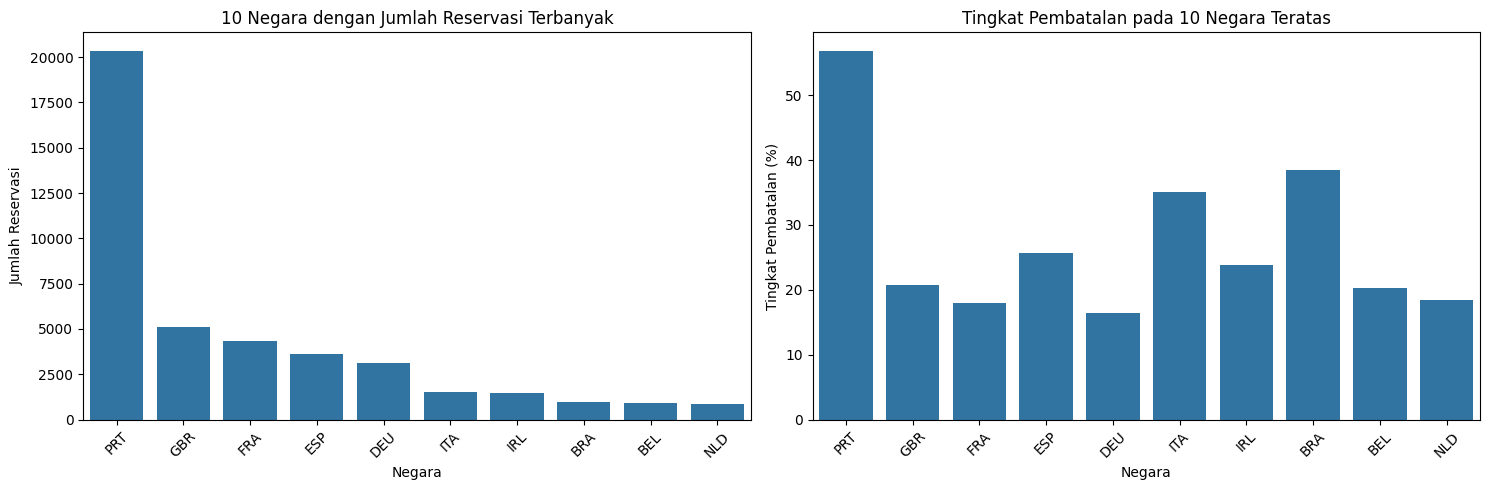

In [210]:
# Visualisasi tingkat pembatalan pada 10 negara dengan reservasi terbanyak
top_10_negara = (df_hotel["country"].value_counts().head(10).index)

df_negara = (df_hotel[df_hotel["country"].isin(top_10_negara)].groupby("country").agg(
        Jumlah_Reservasi=("is_canceled", "size"),
        Jumlah_Dibatalkan=("is_canceled", "sum"),
        Tingkat_Pembatalan=("is_canceled", "mean")
    ).sort_values("Jumlah_Reservasi", ascending=False).reset_index()
)

df_negara["Tingkat_Pembatalan"] = (df_negara["Tingkat_Pembatalan"] * 100)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=df_negara, x="country", y="Jumlah_Reservasi", ax=ax[0])
ax[0].set_title("10 Negara dengan Jumlah Reservasi Terbanyak")
ax[0].set_xlabel("Negara")
ax[0].set_ylabel("Jumlah Reservasi")
ax[0].tick_params(axis="x", rotation=45)

sns.barplot(data=df_negara, x="country", y="Tingkat_Pembatalan", ax=ax[1])
ax[1].set_title("Tingkat Pembatalan pada 10 Negara Teratas")
ax[1].set_xlabel("Negara")
ax[1].set_ylabel("Tingkat Pembatalan (%)")
ax[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


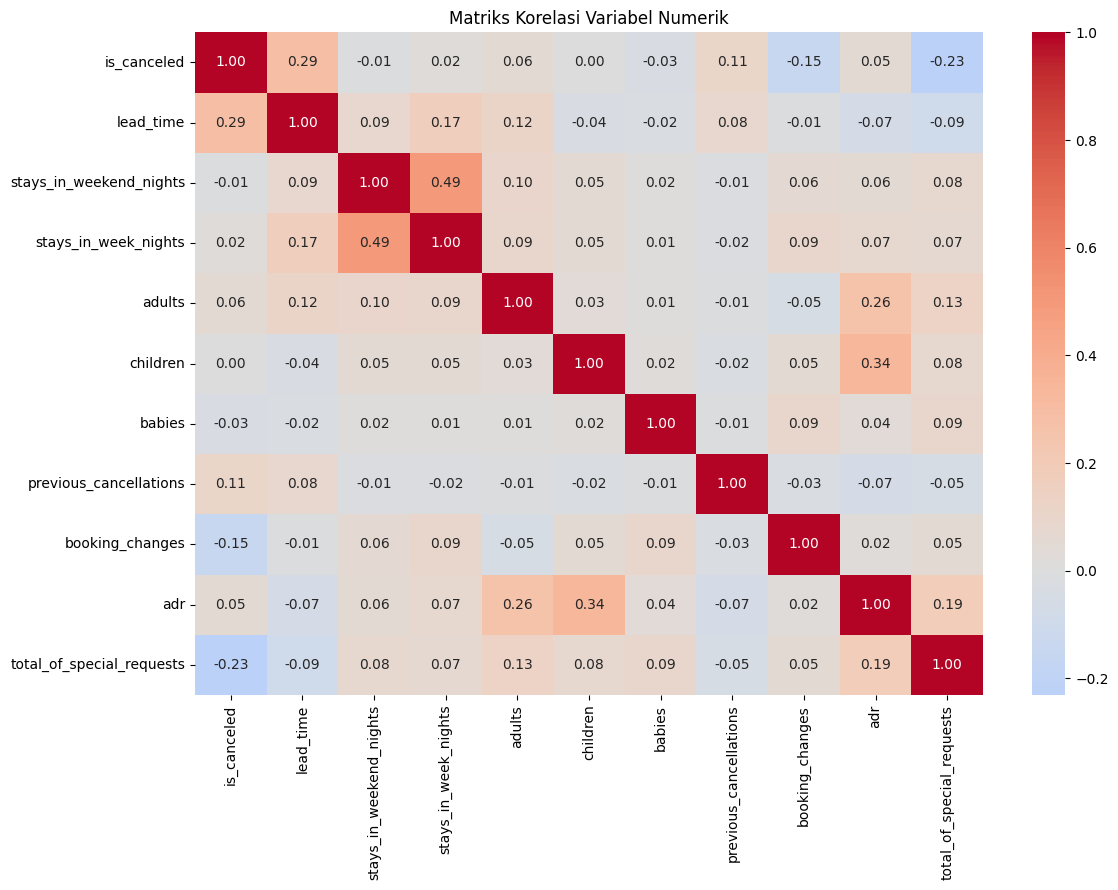

In [211]:
# Visualisasi korelasi antara variabel numerik
kolom_korelasi = [
    "is_canceled",
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "previous_cancellations",
    "booking_changes",
    "adr",
    "total_of_special_requests"
]
matriks_korelasi = df_hotel[kolom_korelasi].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(matriks_korelasi, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriks Korelasi Variabel Numerik")
plt.tight_layout()
plt.show()

- Korelasi positif menunjukkan bahwa nilai variabel cenderung bergerak searah dengan nilai target.
- Korelasi negatif menunjukkan kecenderungan berlawanan arah.
- Nilai mendekati nol menunjukkan hubungan linear yang lemah, tetapi bukan berarti tidak ada hubungan dalam bentuk lain.

Korelasi tidak membuktikan sebab-akibat. Variabel yang tampak berhubungan dengan pembatalan juga perlu ditinjau dari sisi ketersediaannya pada waktu prediksi agar tidak terjadi data leakage.

### 2.5 Representative dan Potensi Bias Sample

In [212]:
# Membandingkan proporsi target pada dataset asli dan sampel
perbandingan_target = pd.DataFrame({
    "Dataset Asli (%)": df ["is_canceled"].value_counts(
        normalize=True).sort_index() * 100,
    "Dataset Sampel (%)": df_hotel["is_canceled"].value_counts(
        normalize=True).sort_index() * 100,
})
perbandingan_target.index.name = "is_canceled"
perbandingan_target.round(2)

,Dataset Asli (%),Dataset Sampel (%)
is_canceled,,
0,62.96,62.84
1,37.04,37.16


In [213]:
# Membandingkan proporsi jenis hotel pada dataset asli dan sampel
perbandingan_hotel = pd.DataFrame({
    "Dataset Asli (%)": (
        df["hotel"].value_counts(normalize=True) * 100
    ),
    "Sampel (%)": (
        df_hotel["hotel"].value_counts(normalize=True) * 100
    )
})

perbandingan_hotel.index.name = "Jenis Hotel"

display(perbandingan_hotel.round(2))

,Dataset Asli (%),Sampel (%)
Jenis Hotel,,
City Hotel,66.45,66.49
Resort Hotel,33.55,33.51


In [214]:
# Membandingkan proporsi tahun kedatangan
perbandingan_tahun = pd.DataFrame({
    "Dataset Asli (%)": (
        df["arrival_date_year"].value_counts(normalize=True) * 100
    ),
    "Sampel (%)": (
        df_hotel["arrival_date_year"].value_counts(normalize=True) * 100
    )
})

perbandingan_tahun.index.name = "Tahun Kedatangan"

display(perbandingan_tahun.sort_index().round(2))

,Dataset Asli (%),Sampel (%)
Tahun Kedatangan,,
2015,18.42,18.46
2016,47.50,47.36
2017,34.08,34.18


### 2.6 Ringkasan Temuan Data

In [215]:
# Ringkasan awal kualitas data
total_baris = len(df_hotel)
total_kolom = df_hotel.shape[1]

jumlah_missing = int(df_hotel.isnull().sum().sum())
jumlah_duplikat = int(df_hotel.duplicated().sum())

jumlah_batal = int((df_hotel["is_canceled"] == 1).sum())
jumlah_tidak_batal = int((df_hotel["is_canceled"] == 0).sum())

total_nights = (
    df_hotel["stays_in_weekend_nights"]
    + df_hotel["stays_in_week_nights"]
)

total_guests = (
    df_hotel["adults"].fillna(0)
    + df_hotel["children"].fillna(0)
    + df_hotel["babies"].fillna(0)
)

ringkasan_data = pd.DataFrame({
    "Indikator": [
        "Jumlah baris sampel",
        "Jumlah kolom sampel",
        "Total nilai kosong pada seluruh kolom",
        "Jumlah baris duplikat identik",
        "Reservasi dibatalkan",
        "Reservasi tidak dibatalkan",
        "Reservasi tanpa tamu berdasarkan pemeriksaan",
        "Reservasi dengan ADR negatif",
        "Reservasi dengan ADR nol",
        "Reservasi dengan lama menginap nol malam"
    ],
    "Hasil": [
        total_baris,
        total_kolom,
        jumlah_missing,
        jumlah_duplikat,
        jumlah_batal,
        jumlah_tidak_batal,
        int((total_guests == 0).sum()),
        int((df_hotel["adr"] < 0).sum()),
        int((df_hotel["adr"] == 0).sum()),
        int((total_nights == 0).sum())
    ]
})

display(ringkasan_data)

,Indikator,Hasil
0,Jumlah baris sampel,50000
1,Jumlah kolom sampel,32
2,Total nilai kosong pada seluruh kolom,54206
3,Jumlah baris duplikat identik,10735
4,Reservasi dibatalkan,18580
5,Reservasi tidak dibatalkan,31420
6,Reservasi tanpa tamu berdasarkan pemeriksaan,69
7,Reservasi dengan ADR negatif,1
8,Reservasi dengan ADR nol,780
9,Reservasi dengan lama menginap nol malam,298


## Data Preparation

### 3.1 Kondisi Awal Dataset

In [216]:
# Membuat salinan dataset sampel untuk data preparation
df_clean = df_hotel.copy(deep=True)
print("Ukuran dataset awal:", df_clean.shape)

Ukuran dataset awal: (50000, 32)


In [217]:
# Memastikan kondisi dataset setelah salinan dibuat
print("Total missing value df_hotel : ", df_hotel.isnull().sum().sum()) # dataset sampel asli
print("Total missing value df_clean : ", df_clean.isnull().sum().sum()) # dataset yang telah dibersihkan

print("Missing value df_clean per kolom:")
print(df_clean.isnull().sum().loc[lambda x: x > 0])

Total missing value df_hotel :  54206
Total missing value df_clean :  54206
Missing value df_clean per kolom:
country      209
agent       6842
company    47155
dtype: int64


Salinan df_clean digunakan agar data awal tidak berubah dan bisa dibandingkan dengan hasil akhir.

### 3.2 Periksa Kondisi Awal Dataset

In [218]:

# Menyimpan kondisi awal untuk evaluasi cleaning
kondisi_awal = {
    "Jumlah Baris": len(df_clean),
    "Jumlah Kolom": len(df_clean.columns),
    "Total Missing Value": int(df_clean.isnull().sum().sum()),
    "Total Baris Duplikat": int(df_clean.duplicated().sum())
}
display(pd.DataFrame(list(kondisi_awal.items()), columns=["Kondisi", "Sebelum Cleaning"]))

,Kondisi,Sebelum Cleaning
0,Jumlah Baris,50000
1,Jumlah Kolom,32
2,Total Missing Value,54206
3,Total Baris Duplikat,10735


### 3.3 Menangani Baris Duplikat

In [219]:
# Menghapus baris yang duplikat yang identik
baris_sebelum = len(df_clean)
duplikat_sebelum = int(df_clean.duplicated().sum())

# Tingkat pembatalan sebelum cleaning
pembatalan_sebelum = df_clean["is_canceled"].mean() * 100 

df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Jumlah baris sebelum cleaning:", baris_sebelum)
print("Jumlah duplikat yang dihapus:", duplikat_sebelum)
print("Jumlah baris sesudah cleaning:", len(df_clean))
print(f"Proporsi pembatalan sebelum: {pembatalan_sebelum:.2f}%")
print(f"Proporsi pembatalan sesudah: {df_clean['is_canceled'].mean() * 100:.2f}%")
print("Jumlah sisa baris duplikat:", df_clean.duplicated().sum())

Jumlah baris sebelum cleaning: 50000
Jumlah duplikat yang dihapus: 10735
Jumlah baris sesudah cleaning: 39265
Proporsi pembatalan sebelum: 37.16%
Proporsi pembatalan sesudah: 28.69%
Jumlah sisa baris duplikat: 0


In [220]:
# Memeriksa kondisi missing value pada dataset awal dan dataset cleaning
print("Total missing value pada df_hotel :", df_hotel.isnull().sum().sum())
print("Total missing value pada df_clean :", df_clean.isnull().sum().sum())

print("\nMissing value pada df_hotel per kolom:")
display(df_hotel.isnull().sum().loc[lambda x: x > 0].sort_values(ascending=False))

print("Missing value pada df_clean per kolom:")
display(df_clean.isnull().sum().loc[lambda x: x > 0].sort_values(ascending=False))

Total missing value pada df_hotel : 54206
Total missing value pada df_clean : 42553

Missing value pada df_hotel per kolom:


company    47155
agent       6842
country      209
dtype: int64

Missing value pada df_clean per kolom:


company    36908
agent       5450
country      195
dtype: int64

### 3.4 Menangani Missing Values

In [221]:
# Menangani missing values berdasarkan kondisi kolom
missing_sebelum = df_clean.isnull().sum()

print("Missing values sebelum penanganan:")
display(missing_sebelum[missing_sebelum > 0].sort_values(ascending=False))

# Menghapus company karena lebih dari 80% nilainya kosong
if "company" in df_clean.columns:
    persentase_company = df_clean["company"].isnull().mean() * 100

    if persentase_company > 80:
        df_clean = df_clean.drop(columns=["company"])
        print(f"Kolom company dihapus ({persentase_company:.2f}% kosong)")

# Mengisi nilai kosong pada country
if "country" in df_clean.columns:
    df_clean["country"] = df_clean["country"].fillna("Unknown")

# Mengisi nilai kosong pada agent dengan penanda 0
if "agent" in df_clean.columns:
    df_clean["agent"] = df_clean["agent"].fillna(0)

# Mengisi children yang kosong dengan 0 (tidak ada anak tercatat)
if "children" in df_clean.columns:
    df_clean["children"] = df_clean["children"].fillna(0)

print("\nMissing values setelah penanganan:")
display(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

Missing values sebelum penanganan:


company    36908
agent       5450
country      195
dtype: int64

Kolom company dihapus (94.00% kosong)

Missing values setelah penanganan:


Series([], dtype: int64)

In [222]:
# Memeriksa kondisi dataset sumber dan hasil cleaning
print("df_hotel:")
print("Jumlah baris:", len(df_hotel))
print("Jumlah kolom:", len(df_hotel.columns))
print("Total missing value:", df_hotel.isnull().sum().sum())

print("\ndf_clean:")
print("Jumlah baris:", len(df_clean))
print("Jumlah kolom:", len(df_clean.columns))
print("Total missing value:", df_clean.isnull().sum().sum())
print("Jumlah duplikasi:", df_clean.duplicated().sum())


df_hotel:
Jumlah baris: 50000
Jumlah kolom: 32
Total missing value: 54206

df_clean:
Jumlah baris: 39265
Jumlah kolom: 31
Total missing value: 0
Jumlah duplikasi: 2


In [223]:
# Memeriksa jumlah baris duplikat pada sumber data
print("Duplikasi pada df_hotel:", df_hotel.duplicated().sum())

# Memeriksa jumlah baris duplikat pada data hasil cleaning
print("Duplikasi pada df_clean:", df_clean.duplicated().sum())

# Memeriksa jumlah baris sumber data
print("Baris df_hotel:", len(df_hotel))

Duplikasi pada df_hotel: 10735
Duplikasi pada df_clean: 2
Baris df_hotel: 50000


### 3.5 Memeriksa Nilai Tidak Wajar
Pemeriksaan dilakukan **sebelum** penghapusan agar kondisi awalnya tercatat.

In [224]:
total_nights = (
    df_clean["stays_in_weekend_nights"] +
    df_clean["stays_in_week_nights"]
)

total_guests = (
    df_clean["adults"].fillna(0) +
    df_clean["children"].fillna(0) +
    df_clean["babies"].fillna(0)
)

periksa_anomali = {
    "Reservasi tanpa tamu": int((total_guests == 0).sum()),
    "Adults > 10": int((df_clean["adults"] > 10).sum()),
    "ADR negatif": int((df_clean["adr"] < 0).sum()),
    "ADR nol": int((df_clean["adr"] == 0).sum()),
    "Durasi nol malam": int((total_nights == 0).sum()),
    "Durasi > 30 malam": int((total_nights > 30).sum())
}

display(pd.DataFrame(
    periksa_anomali.items(),
    columns=["Kondisi", "Jumlah Baris"]
))

,Kondisi,Jumlah Baris
0,Reservasi tanpa tamu,66
1,Adults > 10,2
2,ADR negatif,1
3,ADR nol,738
4,Durasi nol malam,277
5,Durasi > 30 malam,8


### 3.6 Menghapus Data dengan Kondisi Tidak Valid
Baris yang dihapus: (a) tanpa tamu sama sekali, (b) `adults` > 10 (kemungkinan salah catat), (c) ADR negatif, dan (d) lama menginap 0 malam, karena reservasi tanpa malam menginap bukan menginap yang wajar. ADR = 0 dan menginap > 30 malam **dipertahankan** karena masih bisa sah (mis. kamar komplimenter, menginap panjang).

In [225]:
baris_sebelum = len(df_clean)

total_nights = (
    df_clean["stays_in_weekend_nights"] +
    df_clean["stays_in_week_nights"]
)

total_guests = (
    df_clean["adults"] +
    df_clean["children"].fillna(0) +
    df_clean["babies"]
)

# Reservasi tanpa tamu dan ADR negatif ditinjau sebagai anomali
invalid = (total_guests == 0) | (df_clean["adults"] > 10) | (df_clean["adr"] < 0) | (total_nights == 0)

print(f"Tingkat pembatalan pada baris yang akan dihapus: {df_clean.loc[invalid, 'is_canceled'].mean() * 100:.2f}%")
df_clean = df_clean[~invalid].reset_index(drop=True)

print(f"Jumlah baris sebelum dihapus : {baris_sebelum}")
print(f"Jumlah baris setelah dihapus : {len(df_clean)}")
print(f"Total baris yang dihapus     : {baris_sebelum - len(df_clean)}")

# Memeriksa ulang kondisi dataset
print("\nPemeriksaan ulang kondisi dataset setelah cleaning:")
total_nights = df_clean["stays_in_weekend_nights"] + df_clean["stays_in_week_nights"]
total_guests = df_clean["adults"] + df_clean["children"].fillna(0) + df_clean["babies"]

print("Reservasi tanpa tamu :", (total_guests == 0).sum())
print("Reservasi adults > 10:", (df_clean["adults"] > 10).sum())
print("Reservasi ADR negatif:", (df_clean["adr"] < 0).sum())
print("Reservasi 0 malam    :", (total_nights == 0).sum())

Tingkat pembatalan pada baris yang akan dihapus: 6.17%
Jumlah baris sebelum dihapus : 39265
Jumlah baris setelah dihapus : 38941
Total baris yang dihapus     : 324

Pemeriksaan ulang kondisi dataset setelah cleaning:
Reservasi tanpa tamu : 0
Reservasi adults > 10: 0
Reservasi ADR negatif: 0
Reservasi 0 malam    : 0


### 3.7 Memeriksa Kandidat Outlier setelah Cleaning

In [226]:
kolom_iqr = [
    "lead_time",
    "adr",
    "adults",
    "children",
    "babies",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "days_in_waiting_list"
]

hasil_iqr_bersih = []

for kolom in kolom_iqr:
    data = df_clean[kolom].dropna()

    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    iqr = q3 - q1

    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr

    kandidat = (data < batas_bawah) | (data > batas_atas)

    hasil_iqr_bersih.append({
        "Kolom": kolom,
        "Batas Bawah": batas_bawah,
        "Batas Atas": batas_atas,
        "Jumlah Kandidat Outlier": int(kandidat.sum()),
        "Persentase (%)": kandidat.mean() * 100
    })

display(pd.DataFrame(hasil_iqr_bersih).round(2))

,Kolom,Batas Bawah,Batas Atas,Jumlah Kandidat Outlier,Persentase (%)
0,lead_time,-166.50,309.50,1053,2.70
1,adr,-18.73,223.88,1130,2.90
2,adults,2.00,2.00,10087,25.90
3,children,0.00,0.00,3481,8.94
4,babies,0.00,0.00,381,0.98
5,stays_in_weekend_nights,-3.00,5.00,83,0.21
6,stays_in_week_nights,-2.00,6.00,1351,3.47
7,days_in_waiting_list,0.00,0.00,491,1.26


### 3.8 Validasi Kondisi dan Tipe Data

In [227]:
# Membandingkan kondisi awal dan kondisi setelah cleaning
kondisi_akhir = {
    "Jumlah Baris": len(df_clean),
    "Jumlah Kolom": df_clean.shape[1],
    "Total Missing Value": int(df_clean.isnull().sum().sum()),
    "Jumlah Baris Duplikat": int(df_clean.duplicated().sum())
}

perbandingan_kondisi = pd.DataFrame(
    [kondisi_awal, kondisi_akhir],
    index=["Sebelum Cleaning", "Sesudah Cleaning"]
)

display(perbandingan_kondisi)

# Validasi tipe data setelah cleaning
df_clean.info()

,Jumlah Baris,Jumlah Kolom,Total Missing Value,Total Baris Duplikat,Jumlah Baris Duplikat
Sebelum Cleaning,50000,32,54206,10735.0,NaN
Sesudah Cleaning,38941,31,0,NaN,2.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38941 entries, 0 to 38940
Data columns (total 31 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   hotel                           38941 non-null  object 
 1   is_canceled                     38941 non-null  int64  
 2   lead_time                       38941 non-null  int64  
 3   arrival_date_year               38941 non-null  int64  
 4   arrival_date_month              38941 non-null  object 
 5   arrival_date_week_number        38941 non-null  int64  
 6   arrival_date_day_of_month       38941 non-null  int64  
 7   stays_in_weekend_nights         38941 non-null  int64  
 8   stays_in_week_nights            38941 non-null  int64  
 9   adults                          38941 non-null  int64  
 10  children                        38941 non-null  float64
 11  babies                          38941 non-null  int64  
 12  meal                            

### 3.9 Feature Selection: Pencegahan Data Leakage

Model hanya boleh memakai informasi yang sudah diketahui **saat reservasi dibuat**. Memakai informasi yang baru diketahui setelah kejadian membuat skor terlihat tinggi tetapi gagal di dunia nyata (*data leakage*). Kolom yang dibuang:
- `reservation_status` dan `reservation_status_date`: berisi hasil akhir reservasi (Canceled / Check-Out / No-Show), sehingga langsung membocorkan target.
- `assigned_room_type`: tipe kamar yang benar-benar diberikan, baru diketahui saat tamu tiba.
- `required_car_parking_spaces` dan `booking_changes`: dicatat sepanjang masa reservasi sampai check-in atau pembatalan. Reservasi yang sudah batal tidak lagi sempat meminta parkir atau mengubah pesanan, sehingga nilainya ikut "membocorkan" target. Buktinya dicetak pada sel di bawah.
- `arrival_date_year`, `arrival_date_week_number`, `arrival_date_day_of_month`: pola musiman sudah diwakili `arrival_date_month`, dan tahun tidak bisa digeneralisasi ke masa depan.
- `company` sudah dibuang pada tahap missing value (94% kosong).

In [228]:
# Membuang kolom yang menyebabkan data leakage dan kolom yang tidak diperlukan
kolom_leakage = [
    "reservation_status",
    "reservation_status_date",
    "assigned_room_type"
]

# Hanya menghapus kolom yang benar-benar tersedia
kolom_dihapus = [kolom for kolom in kolom_leakage if kolom in df_clean.columns]
df_clean = df_clean.drop(columns=kolom_dihapus)

print("Kolom yang dihapus:", kolom_dihapus)
print("Ukuran dataset setelah feature selection:", df_clean.shape)
print("Total missing values:", df_clean.isnull().sum().sum())

display(df_clean.head())

Kolom yang dihapus: ['reservation_status', 'reservation_status_date', 'assigned_room_type']
Ukuran dataset setelah feature selection: (38941, 28)
Total missing values: 0


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,previous_bookings_not_canceled,reserved_room_type,booking_changes,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests
0,Resort Hotel,0,203,2016,December,49,2,2,5,2,...,0,F,4,No Deposit,250.0,0,Transient,66.8,0,0
1,City Hotel,1,82,2015,July,29,16,0,3,2,...,0,A,0,No Deposit,9.0,0,Transient,76.5,0,0
2,City Hotel,0,25,2016,December,53,27,0,3,3,...,0,A,2,No Deposit,220.0,0,Transient-Party,60.0,0,1
3,City Hotel,0,1,2016,March,11,9,0,1,1,...,0,A,0,No Deposit,9.0,0,Transient-Party,95.0,0,0
4,City Hotel,0,70,2017,April,16,16,2,2,2,...,0,A,0,No Deposit,9.0,0,Transient,108.0,0,0


### 3.10 Menyimpan Dataset Hasil Data Preparation

In [229]:
# Ekspor data yang sudah dibersihkan
df_clean.to_csv("hotel_bookings_clean.csv", index=False)

print("Dataset berhasil disimpan sebagai hotel_bookings_clean.csv")
print("Ukuran akhir dataset:", df_clean.shape)

Dataset berhasil disimpan sebagai hotel_bookings_clean.csv
Ukuran akhir dataset: (38941, 28)


### 3.11 Ringkasan Tingkat Pembatalan pada Data Bersih

In [248]:
# Tingkat pembatalan (%) pada data bersih untuk beberapa faktor utama
df_summary = df_clean.copy()
df_summary["lead_time_category"] = pd.cut(df_summary["lead_time"], bins=[-1, 30, 90, 180, df_summary["lead_time"].max()],
                                          labels=["<= 30 hari", "31 - 90 hari", "91 - 180 hari", "> 180 hari"])

for col in ["hotel", "deposit_type", "market_segment", "customer_type", "total_of_special_requests", "lead_time_category"]:
    rate = (df_summary.groupby(col, observed=True)["is_canceled"].mean() * 100).round(1)
    print(f"--- {col}")
    print(rate.to_string(), "\n")

print("Baris yang identik pada seluruh fitur yang dipakai:", df_clean.duplicated().sum())

--- hotel
hotel
City Hotel      31.7
Resort Hotel    24.2 

--- deposit_type
deposit_type
No Deposit    27.4
Non Refund    96.7
Refundable    24.3 

--- market_segment
market_segment
Aviation         21.5
Complementary    11.7
Corporate        13.1
Direct           14.9
Groups           34.1
Offline TA/TO    17.1
Online TA        36.4 

--- customer_type
customer_type
Contract           18.4
Group               8.6
Transient          31.7
Transient-Party    17.4 

--- total_of_special_requests
total_of_special_requests
0    35.1
1    22.8
2    22.7
3    17.6
4    10.1
5     5.6 

--- lead_time_category
lead_time_category
<= 30 hari       17.0
31 - 90 hari     32.7
91 - 180 hari    36.2
> 180 hari       42.6 

Baris yang identik pada seluruh fitur yang dipakai: 514


## Feature Engineering

In [231]:
# Membuat salinan untuk feature engineering
df_fe = df_clean.copy()

# Feature creation: menggabungkan beberapa kolom menjadi fitur yang lebih informatif
df_fe["total_nights"] = df_fe["stays_in_weekend_nights"] + df_fe["stays_in_week_nights"]
df_fe["total_guests"] = df_fe["adults"] + df_fe["children"] + df_fe["babies"]
df_fe["has_children"] = ((df_fe["children"] + df_fe["babies"]) > 0).astype(int)   # binary feature

df_fe[["total_nights", "total_guests", "has_children"]].head()

,total_nights,total_guests,has_children
0,7,2.0,0
1,3,2.0,0
2,3,3.0,0
3,1,1.0,0
4,4,2.0,0


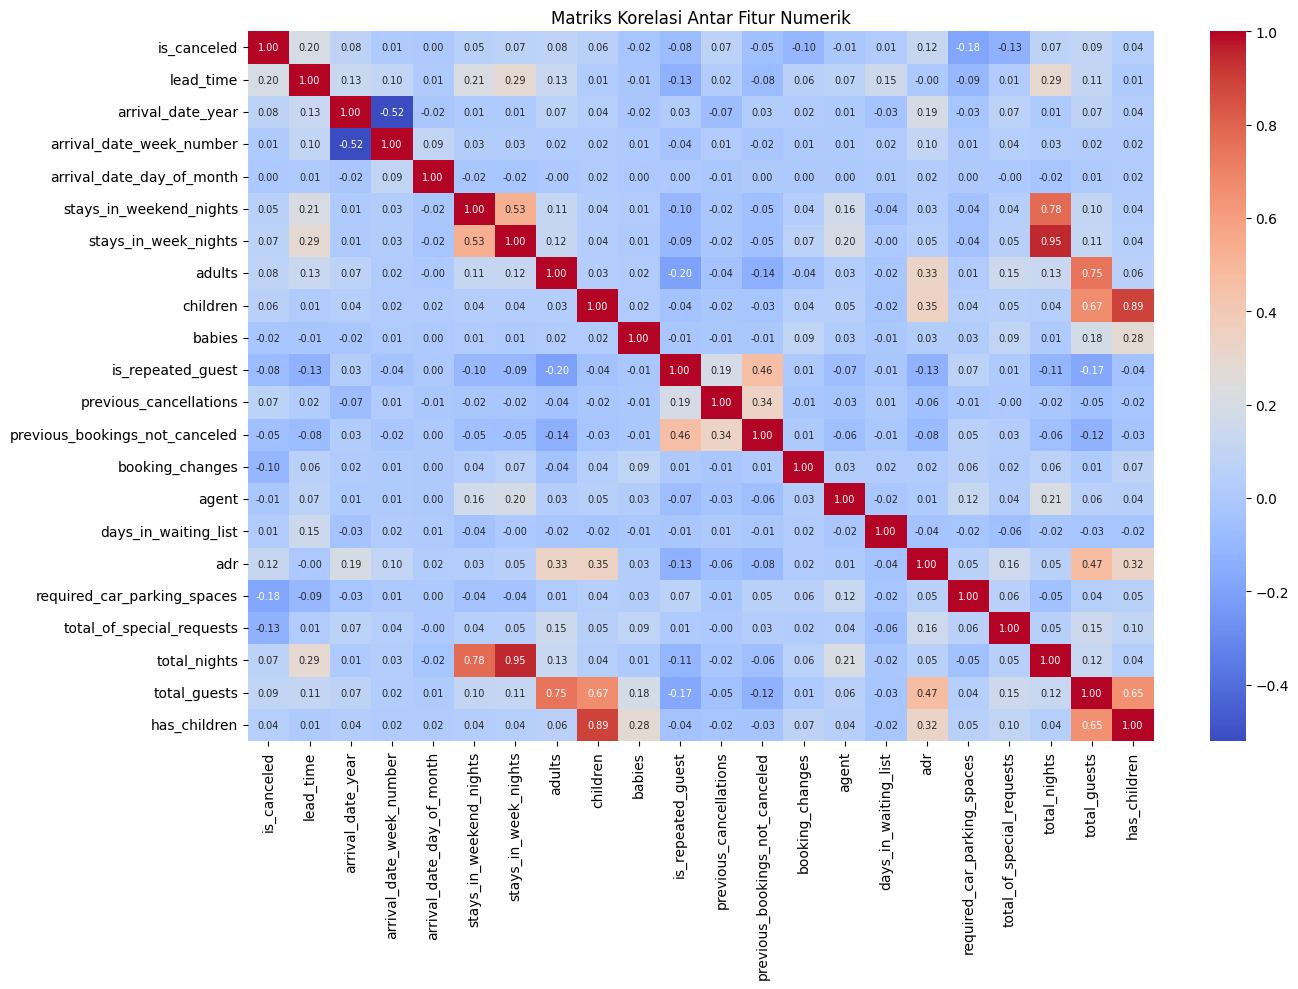

In [232]:
# Visualisasi korelasi antar fitur numerik
num_corr = df_fe.corr(numeric_only=True)

plt.figure(figsize=(14, 10))
sns.heatmap(num_corr, annot=True, fmt=".2f", cmap="coolwarm", annot_kws={"size": 7})
plt.title("Matriks Korelasi Antar Fitur Numerik")
plt.tight_layout()
plt.show()

In [233]:
# Label encoding untuk hotel (hanya dua kategori)
label_encoder = LabelEncoder()
df_fe["hotel"] = label_encoder.fit_transform(df_fe["hotel"])
print("Kelas hotel:", dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))))

Kelas hotel: {'City Hotel': np.int64(0), 'Resort Hotel': np.int64(1)}


In [234]:
# Ordinal encoding untuk bulan kedatangan berdasarkan urutan kalender
month_order = ["January", "February", "March", "April", "May", "June", "July",
               "August", "September", "October", "November", "December"]
df_fe["arrival_date_month"] = df_fe["arrival_date_month"].map({m: i + 1 for i, m in enumerate(month_order)})
df_fe[["arrival_date_month"]].head()

,arrival_date_month
0,12
1,7
2,12
3,3
4,4


In [235]:
# Frequency encoding untuk country dan agent (kategori terlalu banyak jika di-one-hot)
for col in ["country", "agent"]:
    df_fe[col + "_freq"] = df_fe[col].map(df_fe[col].value_counts(normalize=True))
df_fe = df_fe.drop(columns=["country", "agent"])

df_fe[["country_freq", "agent_freq"]].head()

,country_freq,agent_freq
0,0.119514,0.031484
1,0.318764,0.321974
2,0.022881,0.000822
3,0.009502,0.321974
4,0.119514,0.321974


In [236]:
# One-hot encoding untuk kolom kategorikal nominal
ohe_cols = ["meal", "market_segment", "distribution_channel", "reserved_room_type", "deposit_type", "customer_type"]
df_fe = pd.get_dummies(df_fe, columns=ohe_cols, dtype=int)

print("Ukuran dataset setelah encoding:", df_fe.shape)
print("Kolom non-numerik tersisa:", list(df_fe.select_dtypes(exclude=np.number).columns))

Ukuran dataset setelah encoding: (38941, 58)
Kolom non-numerik tersisa: []


## Modelling

### Splitting Dataset

In [237]:
# Mendefinisikan target dan memisahkan fitur
target = "is_canceled"
X = df_fe.drop(columns=target)
y = df_fe[target]

print("Ukuran fitur :", X.shape)
print("Ukuran target:", y.shape)

Ukuran fitur : (38941, 57)
Ukuran target: (38941,)


In [238]:
# Membagi data latih dan data uji (80:20) dengan stratifikasi
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)
print("Proporsi pembatalan data latih:", round(y_train.mean() * 100, 2), "%")
print("Proporsi pembatalan data uji  :", round(y_test.mean() * 100, 2), "%")

(31152, 57) (7789, 57)
(31152,) (7789,)
Proporsi pembatalan data latih: 28.87 %
Proporsi pembatalan data uji  : 28.87 %


### Pemilihan Fitur 
Pemilihan fitur memakai metode *filter* berbasis korelasi (seperti pada praktikum): fitur dengan korelasi absolut terhadap target di bawah 0,05 dibuang. Korelasi dihitung hanya pada **data latih** agar data uji tidak ikut memengaruhi pemilihan fitur.

In [239]:
# Menghitung korelasi tiap fitur dengan target pada data latih
train = X_train.copy()
train[target] = y_train

korelasi = train.corr()[target].drop(target).abs().sort_values(ascending=False)
print(korelasi.head(15))

deposit_type_Non Refund          0.223777
deposit_type_No Deposit          0.218651
lead_time                        0.201207
market_segment_Online TA         0.190450
agent_freq                       0.188680
required_car_parking_spaces      0.182142
distribution_channel_TA/TO       0.154703
country_freq                     0.133726
total_of_special_requests        0.129825
distribution_channel_Direct      0.123612
customer_type_Transient          0.123486
market_segment_Direct            0.119542
adr                              0.118613
market_segment_Offline TA/TO     0.116104
customer_type_Transient-Party    0.105914
Name: is_canceled, dtype: float64


In [240]:
# Memilih fitur dengan korelasi absolut >= 0,05
fitur_terpilih = korelasi[korelasi >= 0.05].index
print("Jumlah fitur terpilih:", len(fitur_terpilih), "dari", X_train.shape[1])
print(list(fitur_terpilih))

X_train_sel = X_train[fitur_terpilih]
X_test_sel = X_test[fitur_terpilih]
print(X_train_sel.shape, X_test_sel.shape)

Jumlah fitur terpilih: 29 dari 57
['deposit_type_Non Refund', 'deposit_type_No Deposit', 'lead_time', 'market_segment_Online TA', 'agent_freq', 'required_car_parking_spaces', 'distribution_channel_TA/TO', 'country_freq', 'total_of_special_requests', 'distribution_channel_Direct', 'customer_type_Transient', 'market_segment_Direct', 'adr', 'market_segment_Offline TA/TO', 'customer_type_Transient-Party', 'booking_changes', 'total_guests', 'adults', 'is_repeated_guest', 'distribution_channel_Corporate', 'hotel', 'market_segment_Corporate', 'arrival_date_year', 'previous_cancellations', 'total_nights', 'stays_in_week_nights', 'children', 'meal_SC', 'previous_bookings_not_canceled']
(31152, 29) (7789, 29)


### Scaling Data
SVM sensitif terhadap skala fitur, sehingga dilengkapi `StandardScaler` di dalam `Pipeline` (seperti pada praktikum; scaler hanya di-*fit* pada data latih). Decision Tree dan Random Forest tidak sensitif terhadap skala fitur, sehingga dilatih tanpa scaling.

### Tuning Hyperparameter
Kedalaman pohon (`max_depth`) dipilih secara manual (seperti pada Modul Random Forest). Agar data uji tidak dipakai untuk memilih parameter, data latih dibagi lagi menjadi data latih dan data validasi, lalu `max_depth` dengan F1-Score kelas 1 (dibatalkan) tertinggi pada data validasi yang dipilih.

In [241]:
# Membagi data latih menjadi data latih dan data validasi untuk memilih max_depth
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_sel, y_train, test_size=0.25, random_state=42, stratify=y_train
)

depth_options = [5, 10, 15, 20, None]
tuning_rows = []
for depth in depth_options:
    dt = DecisionTreeClassifier(max_depth=depth, min_samples_split=20, random_state=42).fit(X_tr, y_tr)
    rf = RandomForestClassifier(n_estimators=100, max_depth=depth, random_state=42, n_jobs=-1).fit(X_tr, y_tr)
    tuning_rows.append({
        "max_depth": str(depth),
        "F1 Decision Tree": classification_report(y_val, dt.predict(X_val), output_dict=True)["1"]["f1-score"],
        "F1 Random Forest": classification_report(y_val, rf.predict(X_val), output_dict=True)["1"]["f1-score"],
    })

df_tuning = pd.DataFrame(tuning_rows).set_index("max_depth").round(4)
display(df_tuning)

best_depth_dt = depth_options[df_tuning["F1 Decision Tree"].values.argmax()]
best_depth_rf = depth_options[df_tuning["F1 Random Forest"].values.argmax()]
print("max_depth terbaik Decision Tree:", best_depth_dt)
print("max_depth terbaik Random Forest:", best_depth_rf)

,F1 Decision Tree,F1 Random Forest
max_depth,,
5,0.6419,0.4485
10,0.6817,0.6464
15,0.6766,0.6961
20,0.6524,0.7043
None,0.6491,0.7027


max_depth terbaik Decision Tree: 10
max_depth terbaik Random Forest: 20


### Pelatihan Model

In [242]:
# Membuat dan melatih tiga model klasifikasi pada seluruh data latih
models = {
    "SVM (Linear)": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="linear")),
    ]),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=best_depth_dt, min_samples_split=20, criterion="gini", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=best_depth_rf, criterion="gini", random_state=42, n_jobs=-1
    ),
}

for name, model in models.items():
    model.fit(X_train_sel, y_train)
    print(f"Model {name} berhasil dilatih")

Model SVM (Linear) berhasil dilatih
Model Decision Tree berhasil dilatih
Model Random Forest berhasil dilatih


### Prediksi

In [243]:
# Memprediksi data uji dan menampilkan contoh hasil prediksi
predictions = {name: model.predict(X_test_sel) for name, model in models.items()}

nama_kelas = {0: "Tidak batal", 1: "Batal"}
hasil = pd.DataFrame({
    "Label sebenarnya": y_test.iloc[:8].map(nama_kelas).values,
    "SVM": pd.Series(predictions["SVM (Linear)"][:8]).map(nama_kelas).values,
    "Decision Tree": pd.Series(predictions["Decision Tree"][:8]).map(nama_kelas).values,
    "Random Forest": pd.Series(predictions["Random Forest"][:8]).map(nama_kelas).values,
})
print(hasil)

  Label sebenarnya          SVM Decision Tree Random Forest
0      Tidak batal  Tidak batal   Tidak batal   Tidak batal
1      Tidak batal  Tidak batal   Tidak batal   Tidak batal
2      Tidak batal  Tidak batal   Tidak batal   Tidak batal
3      Tidak batal  Tidak batal   Tidak batal   Tidak batal
4            Batal  Tidak batal   Tidak batal   Tidak batal
5            Batal        Batal         Batal         Batal
6      Tidak batal  Tidak batal   Tidak batal   Tidak batal
7      Tidak batal  Tidak batal   Tidak batal   Tidak batal


## Evaluation

Confusion matrix - SVM (Linear)
                        Diprediksi tidak batal  Diprediksi batal
Sebenarnya tidak batal                    5115               425
Sebenarnya batal                          1148              1101 

Confusion matrix - Decision Tree
                        Diprediksi tidak batal  Diprediksi batal
Sebenarnya tidak batal                    4955               585
Sebenarnya batal                           759              1490 

Confusion matrix - Random Forest
                        Diprediksi tidak batal  Diprediksi batal
Sebenarnya tidak batal                    5073               467
Sebenarnya batal                           768              1481 



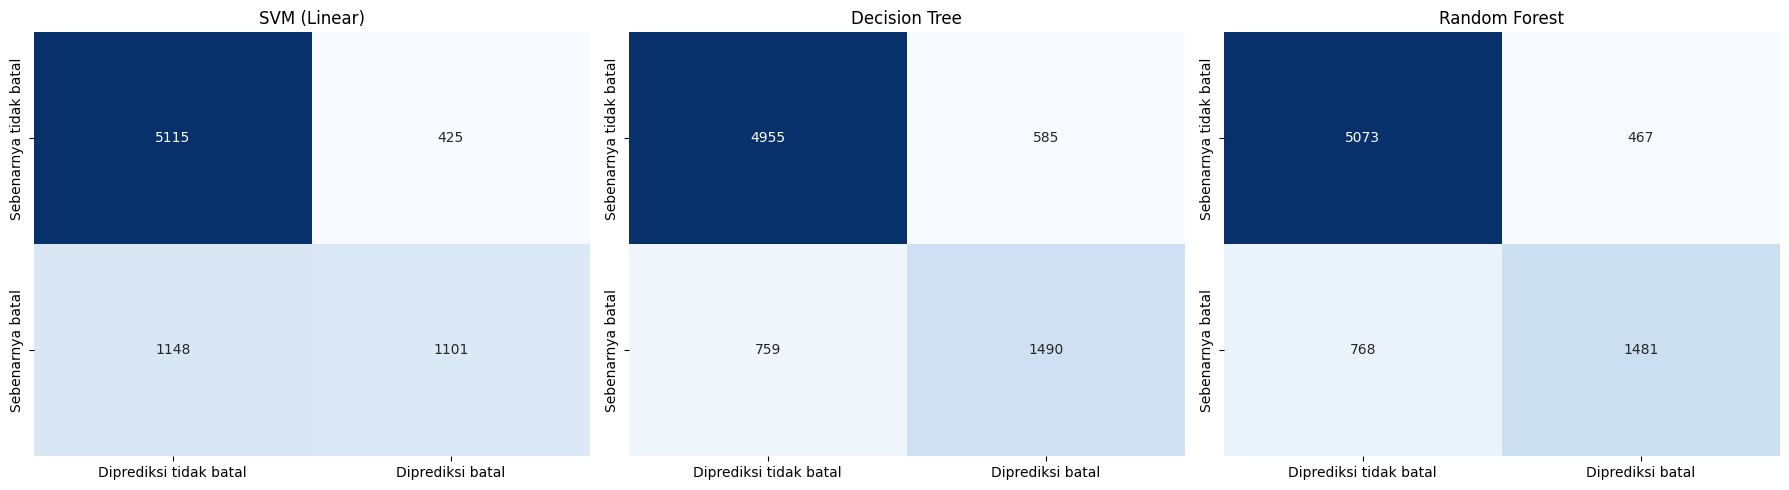

In [244]:
# Confusion matrix tiap model
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for axis, (name, y_pred) in zip(ax, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    cm_df = pd.DataFrame(cm, index=["Sebenarnya tidak batal", "Sebenarnya batal"],
                         columns=["Diprediksi tidak batal", "Diprediksi batal"])
    print(f"Confusion matrix - {name}")
    print(cm_df, "\n")
    sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues", ax=axis, cbar=False)
    axis.set_title(name)

plt.tight_layout()
plt.show()

In [245]:
# Classification report tiap model
for name, y_pred in predictions.items():
    print(f"=== {name} ===")
    print(classification_report(y_test, y_pred, target_names=["Tidak batal", "Batal"]))

=== SVM (Linear) ===
              precision    recall  f1-score   support

 Tidak batal       0.82      0.92      0.87      5540
       Batal       0.72      0.49      0.58      2249

    accuracy                           0.80      7789
   macro avg       0.77      0.71      0.73      7789
weighted avg       0.79      0.80      0.78      7789

=== Decision Tree ===
              precision    recall  f1-score   support

 Tidak batal       0.87      0.89      0.88      5540
       Batal       0.72      0.66      0.69      2249

    accuracy                           0.83      7789
   macro avg       0.79      0.78      0.78      7789
weighted avg       0.82      0.83      0.83      7789

=== Random Forest ===
              precision    recall  f1-score   support

 Tidak batal       0.87      0.92      0.89      5540
       Batal       0.76      0.66      0.71      2249

    accuracy                           0.84      7789
   macro avg       0.81      0.79      0.80      7789
weighted 

In [246]:
# Membandingkan performa model pada kelas "Batal" (kelas 1)
rows = []
for name, y_pred in predictions.items():
    rep = classification_report(y_test, y_pred, output_dict=True)
    cm = confusion_matrix(y_test, y_pred)
    rows.append({
        "Model": name,
        "Accuracy": rep["accuracy"],
        "Precision (Batal)": rep["1"]["precision"],
        "Recall (Batal)": rep["1"]["recall"],
        "F1-Score (Batal)": rep["1"]["f1-score"],
        "False Positive": cm[0, 1],
        "False Negative": cm[1, 0],
    })

df_eval = pd.DataFrame(rows).set_index("Model").round(4)
display(df_eval)

best_model_name = df_eval["F1-Score (Batal)"].idxmax()
print("Model terbaik berdasarkan F1-Score kelas Batal:", best_model_name)

,Accuracy,Precision (Batal),Recall (Batal),F1-Score (Batal),False Positive,False Negative
Model,,,,,,
SVM (Linear),0.7980,0.7215,0.4896,0.5833,425,1148
Decision Tree,0.8274,0.7181,0.6625,0.6892,585,759
Random Forest,0.8414,0.7603,0.6585,0.7057,467,768


Model terbaik berdasarkan F1-Score kelas Batal: Random Forest


                        Feature  Importance
2                     lead_time    0.163315
7                  country_freq    0.131841
12                          adr    0.098257
4                    agent_freq    0.090944
8     total_of_special_requests    0.081948
24                 total_nights    0.046553
25         stays_in_week_nights    0.041195
5   required_car_parking_spaces    0.039005
22            arrival_date_year    0.037397
3      market_segment_Online TA    0.030146
0       deposit_type_Non Refund    0.028223
23       previous_cancellations    0.027650
1       deposit_type_No Deposit    0.025719
15              booking_changes    0.025124
10      customer_type_Transient    0.018072


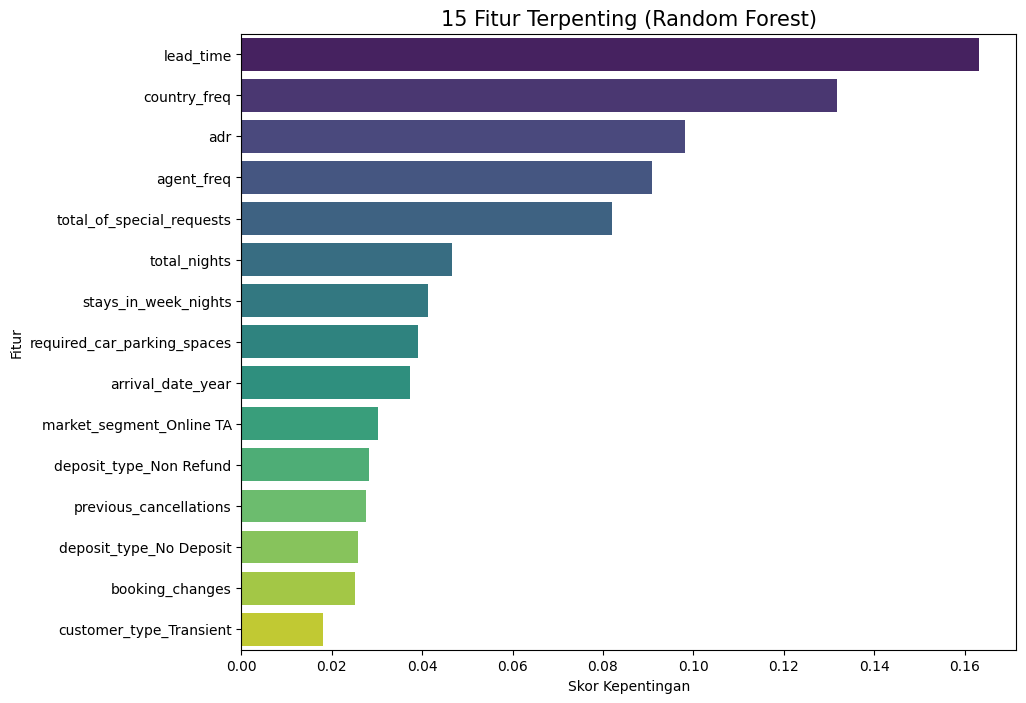

In [247]:
# Analisis feature importance dari Random Forest
rf_model = models["Random Forest"]

feature_importance_df = pd.DataFrame({
    "Feature": X_train_sel.columns,
    "Importance": rf_model.feature_importances_,
}).sort_values(by="Importance", ascending=False)

print(feature_importance_df.head(15))

plt.figure(figsize=(10, 8))
sns.barplot(x="Importance", y="Feature", data=feature_importance_df.head(15), hue="Feature", palette="viridis", legend=False)
plt.title("15 Fitur Terpenting (Random Forest)", fontsize=15)
plt.xlabel("Skor Kepentingan")
plt.ylabel("Fitur")
plt.show()

## Penjelasan Analisis dan Rekomendasi Strategi *Overbooking*

### Ringkasan Hasil
Setelah deduplikasi dan pembersihan, data pemodelan berisi 38.941 reservasi dengan tingkat pembatalan 28,87%. Pemilihan fitur berbasis korelasi mempertahankan 28 dari 54 fitur. Tiga algoritma dibandingkan pada data uji (7.789 reservasi):

| Model | Accuracy | Precision (Batal) | Recall (Batal) | F1-Score (Batal) |
|---|---|---|---|---|
| SVM (Linear) | 0,795 | 0,716 | 0,480 | 0,574 |
| Decision Tree | 0,815 | 0,706 | 0,615 | 0,657 |
| Random Forest | 0,836 | 0,752 | 0,643 | 0,694 |

**Random Forest** (`max_depth=20`, dipilih lewat data validasi) memberikan performa terbaik. SVM dengan kernel linear memiliki *recall* terendah; salah satu penyebab yang mungkin adalah batas keputusan lurus kurang mampu menangkap pola yang tidak linear pada data ini, sedangkan model berbasis pohon lebih fleksibel.

### Faktor Risiko Pembatalan
Berdasarkan ringkasan data bersih dan *feature importance* Random Forest:
- **Lead time**: fitur terpenting. Tingkat pembatalan naik dari 17,0% pada lead time sampai 30 hari menjadi 42,6% pada lead time di atas 180 hari.
- **Permintaan khusus**: reservasi tanpa permintaan khusus dibatalkan 35,1%, sedangkan yang memiliki 4 permintaan khusus hanya 10,1%.
- **Kebutuhan tempat parkir**: tidak ada pembatalan pada reservasi yang meminta tempat parkir.
- **Negara dan agent**: `country_freq` dan `agent_freq` termasuk fitur penting, yang menunjukkan bahwa asal tamu dan agent pemesanan berkaitan dengan risiko pembatalan. Karena keduanya di-*encode* dengan frekuensi, grafik ini tidak menunjukkan negara atau agent mana yang berisiko. Pada grafik EDA, Portugal (PRT) tercatat memiliki tingkat pembatalan tertinggi di antara 10 negara terbanyak.
- **ADR dan lama menginap**: `adr`, `total_nights`, dan `stays_in_week_nights` juga berada di jajaran fitur penting.
- **Segmen pasar**: *Online TA* (36,4%) dan *Groups* (34,1%) lebih berisiko dibanding *Direct* (14,9%) dan *Corporate* (13,1%).
- **Tipe hotel**: *City Hotel* (31,7%) lebih tinggi daripada *Resort Hotel* (24,2%).
- **Jenis deposit**: reservasi *Non Refund* memiliki tingkat pembatalan 96,7%. Pola ini berlawanan dengan logika bisnis (deposit tidak dikembalikan seharusnya menahan pembatalan) dan kemungkinan berkaitan dengan cara pencatatan di dataset ini, sehingga perlu diverifikasi dengan pihak hotel sebelum dijadikan dasar kebijakan.

Seluruh temuan di atas adalah **asosiasi**, bukan bukti sebab-akibat. Skor *feature importance* Random Forest juga cenderung lebih tinggi untuk fitur yang memiliki banyak nilai unik, sehingga urutannya perlu dibaca bersama hasil EDA.

### Kaitan dengan Strategi *Overbooking*
Pada konteks *overbooking*, dua jenis kesalahan prediksi memiliki dampak berbeda:
- ***False Positive*** (diprediksi batal, ternyata tamu datang): inilah risiko *overbooking*, karena hotel mungkin harus menolak atau memindahkan tamu. Pada Random Forest terdapat 477 kasus; dari 1.924 reservasi yang diprediksi batal, sekitar 75% benar-benar batal (*precision* 0,752), sehingga sekitar 25% sisanya tetap datang.
- ***False Negative*** (diprediksi tidak batal, ternyata batal): kamar kosong yang tidak diantisipasi. Pada Random Forest terdapat 802 kasus; model berhasil menangkap 64,3% dari seluruh pembatalan (*recall* 0,643).

Jika hotel lebih takut menolak tamu yang datang, *precision* kelas "Batal" yang menjadi fokus. Jika hotel lebih ingin mengisi kamar yang berpotensi kosong, *recall* yang menjadi fokus. Pilihan yang tepat bergantung pada biaya relokasi tamu dibanding pendapatan kamar kosong, yang tidak tersedia di dataset ini. Hasil model sebaiknya dipakai sebagai pendukung keputusan, misalnya untuk menandai reservasi berisiko tinggi (lead time panjang, tanpa permintaan khusus, segmen *Online TA* atau *Groups*), bukan sebagai pengganti pertimbangan manajer hotel.

### Keterbatasan
- Dataset berasal dari dua hotel di Portugal (2015 - 2017), sehingga belum tentu berlaku untuk hotel lain atau periode lain.
- Dataset tidak memiliki ID reservasi, sehingga baris identik dihapus sebagai duplikat. Proporsi pembatalan turun dari 37,16% menjadi 28,69% karena baris duplikat banyak yang berstatus batal. Baris duplikat juga terkonsentrasi pada kategori tertentu (misalnya *Groups*, *Non Refund*, dan Portugal), sehingga angka pada grafik Data Understanding (sebelum pembersihan) lebih tinggi dibanding angka pada data bersih.
- Setelah kolom tertentu dibuang pada tahap *feature selection*, masih ada sekitar 1,7% baris yang identik pada fitur yang dipakai. Baris ini berasal dari reservasi yang berbeda pada kolom yang dibuang (mis. tanggal kedatangan), sehingga dipertahankan.
- Pemilihan fitur berbasis korelasi hanya menangkap hubungan linear, sehingga fitur yang berpengaruh secara tidak linear bisa ikut terbuang. Tuning hanya mencakup `max_depth`, dan SVM hanya memakai kernel linear seperti pada praktikum.
- Model belum memakai informasi biaya, sehingga hasilnya merupakan dasar awal, bukan keputusan operasional.